# 01 — Learning Problem & Exploratory Data Analysis (Bab 4)

**Proyek:** Klasifikasi ujaran kebencian pada wacana informasi pemerintahan Indonesia
**Dataset:** *Indonesian Abusive and Hate Speech Twitter Text* (Ibrohim & Budi, 2019)

Notebook ini hanya **membaca** data mentah. Tidak ada data yang diubah, tidak ada model yang dilatih.
Tujuannya menjawab tiga pertanyaan Bab 4:
1. Data seperti apa yang kita miliki? (4.1–4.2)
2. Apa masalah kualitas data yang harus dibereskan? (4.3)
3. Pola awal apa yang terlihat sebelum pemodelan? (4.4)

> Aturan proyek: kolom `Abusive` dan seluruh `HS_*` **hanya** untuk EDA dan *error analysis*.
> Memasukkannya sebagai fitur `X` = target leakage (label turunan dari target).

In [1]:
# ============================================================
# Konfigurasi global — satu sumber kebenaran untuk path & seed
# ============================================================
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

SEED = 42
# Notebook diasumsikan dijalankan dari folder notebooks/ (Jupyter/Colab/nbconvert).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)
print("RAW :", RAW)

ROOT: D:\SEMESTER 5\TUGAS KELOMPOK PAK NANANG\id-gov-hatespeech-classification
RAW : D:\SEMESTER 5\TUGAS KELOMPOK PAK NANANG\id-gov-hatespeech-classification\data\raw


## 4.1 Informasi Dataset

### Konsep singkat
Sebelum menyentuh model, kita harus tahu **bentuk** data: berapa baris (sampel) dan kolom (variabel),
tipe tiap kolom, ukuran file, dan format penyimpanan. Ini menentukan cara memuat data dan
jenis transformasi yang sah (teks → vektor, kategorik → encoding, numerik → scaling).

In [2]:
df = pd.read_csv(RAW / "data.csv", encoding="latin1")
kamus = pd.read_csv(RAW / "new_kamusalay.csv", encoding="latin1", header=None,
                    names=["slang", "formal"])
abusive = pd.read_csv(RAW / "abusive.csv", encoding="latin1")

print(f"data.csv          : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"new_kamusalay.csv : {len(kamus):,} pasangan kata tidak baku -> baku")
print(f"abusive.csv       : {len(abusive):,} kata pada leksikon kasar")

data.csv          : 13,169 baris x 13 kolom
new_kamusalay.csv : 15,167 pasangan kata tidak baku -> baku
abusive.csv       : 125 kata pada leksikon kasar


In [3]:
for name in ["data.csv", "new_kamusalay.csv", "abusive.csv"]:
    size_mb = (RAW / name).stat().st_size / 1024**2
    print(f"{name:20s} {size_mb:6.2f} MB")
print(f"{'DataFrame di memori':20s} {df.memory_usage(deep=True).sum() / 1024**2:6.2f} MB")

data.csv               1.77 MB
new_kamusalay.csv      0.27 MB
abusive.csv            0.00 MB
DataFrame di memori    3.26 MB


In [4]:
ringkas = pd.DataFrame({
    "kolom": df.columns,
    "tipe": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "n_unik": df.nunique().values,
    "contoh_nilai": [str(df[c].iloc[0])[:70] for c in df.columns],
})
ringkas

,kolom,tipe,non_null,n_unik,contoh_nilai
0,Tweet,str,13169,13023,- disaat semua cowok berusaha melacak perhatian gue. loe lantas remehk
1,HS,int64,13169,2,1
2,Abusive,int64,13169,2,1
3,HS_Individual,int64,13169,2,1
4,HS_Group,int64,13169,2,0
5,HS_Religion,int64,13169,2,0
6,HS_Race,int64,13169,2,0
7,HS_Physical,int64,13169,2,0
8,HS_Gender,int64,13169,2,0
9,HS_Other,int64,13169,2,1


In [5]:
# Lima baris pertama, dibatasi pada kolom yang aman dibaca (teks + target).
df[["Tweet", "HS", "Abusive"]].head(5)

,Tweet,HS,Abusive
0,- disaat semua cowok berusaha melacak perhatian gue. loe lantas remehkan perhatian yg gue kasih khusus ke elo. basic elo cowok bego ! ! !',1,1
1,RT USER: USER siapa yang telat ngasih tau elu?edan sarap gue bergaul dengan cigax jifla calis sama siapa noh licew juga',0,1
2,"41. Kadang aku berfikir, kenapa aku tetap percaya pada Tuhan padahal aku selalu jatuh berkali-kali. Kadang aku merasa Tuhan itu ninggalk...",0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT TAPI DILIAT DARI MANA ITU AKU',0,0
4,USER USER Kaum cebong kapir udah keliatan dongoknya dari awal tambah dongok lagi hahahah',1,1


In [6]:
dist = df["HS"].value_counts().sort_index().rename_axis("HS").to_frame("jumlah")
dist["persen"] = (dist["jumlah"] / len(df) * 100).round(2)
dist.index = ["0 = Non-Hate Speech", "1 = Hate Speech"]
dist

,jumlah,persen
0 = Non-Hate Speech,7608,57.77
1 = Hate Speech,5561,42.23


### Tabel 4.1 — Kamus data

| Kolom | Tipe | Deskripsi | Peran di proyek |
| :--- | :--- | :--- | :--- |
| `Tweet` | teks | Isi cuitan berbahasa Indonesia; `USER`/`URL` sudah dianonimkan oleh pembuat dataset | **Input mentah** ($X_{raw}$) |
| `HS` | biner (0/1) | 1 = ujaran kebencian, 0 = bukan | **Target ($Y$)** |
| `Abusive` | biner (0/1) | 1 = mengandung bahasa kasar | Konteks EDA / error analysis — **bukan fitur** |
| `HS_Individual` | biner | Kebencian menyasar individu | Konteks — bukan fitur |
| `HS_Group` | biner | Kebencian menyasar kelompok | Konteks — bukan fitur |
| `HS_Religion` | biner | Kebencian berbasis agama | Konteks — bukan fitur |
| `HS_Race` | biner | Kebencian berbasis ras/etnis | Konteks — bukan fitur |
| `HS_Physical` | biner | Kebencian menyasar fisik/disabilitas | Konteks — bukan fitur |
| `HS_Gender` | biner | Kebencian berbasis gender/orientasi seksual | Konteks — bukan fitur |
| `HS_Other` | biner | Kebencian lain (hinaan/sindiran) | Konteks — bukan fitur |
| `HS_Weak` / `HS_Moderate` / `HS_Strong` | biner | Tingkat keparahan ujaran | Konteks — bukan fitur |

**Catatan leakage:** `Abusive` sangat berkorelasi dengan `HS` karena dianotasi dari kalimat yang sama.
Memasukkannya ke `X` membuat model "mencontek kunci jawaban" → akurasi uji akan terlihat bagus
tetapi tidak berguna saat dipakai pada data tanpa anotasi manual.

## 4.2 Deskripsi Fitur

Fitur input yang **sah** hanyalah teks `Tweet` (dan turunannya). Rencana fitur turunan:

| Fitur | Jenis | Definisi | Alasan |
| :--- | :--- | :--- | :--- |
| `text_clean_contextual` | teks | Hasil cleaning + normalisasi kamus, stopword **dipertahankan** | Input IndoBERT; negasi ("tidak", "bukan") harus utuh |
| `text_clean_lexical` | teks | Seperti di atas, stopword umum dibuang kecuali negasi | Input TF-IDF; mengurangi dimensi & noise |
| `char_length` | numerik | Jumlah karakter teks mentah | Cuitan panjang = argumen/cerita, pendek = ejekan singkat |
| `word_count` | numerik | Jumlah kata | Alternatif panjang yang tidak terpengaruh spasi |
| `caps_ratio` | numerik | huruf kapital / (panjang + 1) | Indikator "berteriak"/emosi tinggi |
| `exclamation_count` | numerik | Jumlah `!` dan `?` | Intensitas emosi/retoris |
| `user_mention_count` | numerik | Jumlah token `USER` | Cuitan yang menyerang akun tertentu |
| `abusive_lexicon_count` | numerik | Jumlah kata cocok `abusive.csv` | Sinyal leksikal kasar tanpa membocorkan label |
| `is_gov` | biner | Mengandung kata kunci pemerintahan/politik | **Hanya audit SDG 16**, bukan fitur model |

> `is_gov` tidak dipakai sebagai `X` karena proyek ini tidak ingin model belajar "topik = kebencian".
> Fitur ini dipakai untuk mengukur performa pada subgrup wacana pemerintahan.

## 4.3 Analisis Kondisi Data

Empat hal yang diperiksa: **missing values, duplikat, noise teks, dan outlier**.
Untuk klasifikasi, **imbalance** juga diperiksa karena menentukan metrik evaluasi.

In [7]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "persen": (df.isna().mean() * 100).round(2),
})
print(f"Total sel kosong: {df.isna().sum().sum()}")
missing.T

Total sel kosong: 0


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
persen,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
dup_exact = int(df.duplicated(subset=["Tweet"]).sum())

label_per_tweet = df.groupby("Tweet")["HS"].nunique()
konflik = label_per_tweet[label_per_tweet > 1].index
baris_konflik = int(df["Tweet"].isin(konflik).sum())

print(f"Baris duplikat teks exact        : {dup_exact}")
print(f"Tweet dengan label HS bertentangan: {len(konflik)} tweet ({baris_konflik} baris)")
print(f"Sisa baris bila duplikat dibuang  : {len(df) - dup_exact}")

Baris duplikat teks exact        : 146
Tweet dengan label HS bertentangan: 8 tweet (28 baris)
Sisa baris bila duplikat dibuang  : 13023


In [9]:
# Contoh tweet yang labelnya bertentangan -> tidak bisa dipakai sebagai data latih yang jujur.
df[df["Tweet"].isin(konflik)][["Tweet", "HS", "HS_Individual", "HS_Group"]] \
    .sort_values("Tweet").head(8)

,Tweet,HS,HS_Individual,HS_Group
863,"Ekonomi dipegang Gerindra? Bisa hancur negara kita. Masak sarankan cetak uang sebanyak2 utk bayar hutang, jadi gk perlu hutang lg. Malah...",1,0,1
2911,"Ekonomi dipegang Gerindra? Bisa hancur negara kita. Masak sarankan cetak uang sebanyak2 utk bayar hutang, jadi gk perlu hutang lg. Malah...",0,0,0
9822,Kekalahan Suharto-Prabowo melawan opini pada 1998 lebih dikarenakah keterlibatan Konspirasi Global di mana AS - China dan seluruh sekutu...,0,0,0
3069,Kekalahan Suharto-Prabowo melawan opini pada 1998 lebih dikarenakah keterlibatan Konspirasi Global di mana AS - China dan seluruh sekutu...,1,0,1
6109,Masalah dunia dan masalah nafsu ya kang USER . Kata2 kok bersayap kayak burung hantu. URL,0,0,0
8280,Masalah dunia dan masalah nafsu ya kang USER . Kata2 kok bersayap kayak burung hantu. URL,1,1,0
10098,"RT USER: USER Heran juga saya, setan iblis pada kabur dan takut kalo mendengar Azhan, tapi ini mahluk Allah yg satu ini anteng s\xe2\x80...",0,0,0
12933,"RT USER: USER Heran juga saya, setan iblis pada kabur dan takut kalo mendengar Azhan, tapi ini mahluk Allah yg satu ini anteng s\xe2\x80...",1,1,0


In [10]:
tweet_str = df["Tweet"].astype(str)
noise = pd.Series({
    "token USER (anonymized)": tweet_str.str.contains(r"\bUSER\b").sum(),
    "token URL": tweet_str.str.contains(r"\bURL\b").sum(),
    "token RT (retweet)": tweet_str.str.contains(r"\bRT\b").sum(),
    "kode hex \\xNN": tweet_str.str.contains(r"\\x[0-9a-fA-F]{2}").sum(),
    "simbol/tanda baca": tweet_str.str.contains(r"[^A-Za-z0-9\s]").sum(),
    "teks kosong/whitespace": tweet_str.str.strip().eq("").sum(),
})
noise.to_frame("jumlah_baris")

,jumlah_baris
token USER (anonymized),7680
token URL,792
token RT (retweet),942
kode hex \xNN,1435
simbol/tanda baca,12281
teks kosong/whitespace,0


In [11]:
# Contoh nyata noise: kode hex dari encoding latin1 yang gagal.
tweet_str[tweet_str.str.contains(r"\\x[0-9a-fA-F]{2}")].head(3).to_frame("Tweet")

,Tweet
5,USER Ya bani taplak dkk \xf0\x9f\x98\x84\xf0\x9f\x98\x84\xf0\x9f\x98\x84'
10,"Setidaknya gw punya jari tengah buat lu, sebelom gw ukur nyali sama bacot lu \xf0\x9f\x98\x8f'"
17,Ari sarua beki mah repeh monyet\xf0\x9f\x98\x86\xf0\x9f\x98\x86'


In [12]:
chars, words = tweet_str.str.len(), tweet_str.str.split().str.len()
q = chars.quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]).round(1)
iqr = q[0.75] - q[0.25]
batas_atas = q[0.75] + 1.5 * iqr
z = (chars - chars.mean()) / chars.std(ddof=0)

print("Kuantil panjang karakter:")
print(q.to_string())
print(f"\nBatas outlier IQR (Q3 + 1.5*IQR): {batas_atas:.0f} karakter")
print(f"Baris di atas batas IQR          : {(chars > batas_atas).sum()} ({(chars > batas_atas).mean():.2%})")
print(f"Baris dengan |z| > 3             : {(z.abs() > 3).sum()}")
print("\nPanjang kata:", words.describe().round(1).to_dict())
print("Panjang karakter maksimum:", chars.max(), "-> batas tweet Twitter (280)")

Kuantil panjang karakter:
0.00      4.0
0.25     59.0
0.50    100.0
0.75    152.0
0.90    233.0
0.95    250.0
0.99    256.0
1.00    561.0

Batas outlier IQR (Q3 + 1.5*IQR): 292 karakter
Baris di atas batas IQR          : 24 (0.18%)
Baris dengan |z| > 3             : 9

Panjang kata: {'count': 13169.0, 'mean': 17.3, 'std': 10.2, 'min': 1.0, '25%': 9.0, '50%': 15.0, '75%': 23.0, 'max': 52.0}
Panjang karakter maksimum: 561 -> batas tweet Twitter (280)


In [13]:
# Outlier panjang: apakah panjang teks membedakan kelas? (bukan untuk memutuskan hapus/tidak)
per_kelas = df.assign(char_length=chars, word_count=words).groupby("HS")[
    ["char_length", "word_count"]
].agg(["mean", "median", "max"]).round(1)
per_kelas

char_length             word_count           
          mean median  max       mean median max
HS                                              
0        123.0  107.5  561       18.4   16.0  52
1        102.2   94.0  278       15.7   14.0  51

### Interpretasi kondisi data

- **Missing values:** 0 sel kosong. Dataset "rapi secara tabel", tetapi belum tentu bersih secara teks.
- **Duplikat:** 146 baris duplikat teks persis, dan 8 tweet (28 baris) dengan label `HS` bertentangan. Duplikat **wajib** dibuang sebelum split; kalau tidak, teks yang sama bisa muncul di train dan test → skor uji terlalu optimistis (leakage). Tweet berlabel konflik dibuang karena tidak ada dasar objektif untuk memilih salah satu label.
- **Noise:** 7.680 baris memuat token `USER`, 942 `RT`, 792 `URL`, 1.435 memuat kode hex (emoji yang rusak saat encoding latin1), dan 12.281 memuat simbol. Semua harus dinormalisasi; contoh nyata bisa dilihat pada tabel di atas.
- **Outlier panjang:** hanya 24 baris (0,18%) di atas batas IQR, dan panjang maksimum 561 karakter — di atas batas 280 karakter Twitter, tanda ada teks gabungan/gangguan *crawling*. Bukan kesalahan yang layak dihapus: menghapusnya berarti membuang contoh ujaran kebencian yang panjang. Cukup di-*scale*/di-*cap* saat pemodelan.
- **Imbalance:** kelas 0 sedikit lebih banyak (1,37:1). Ini **ringan**, bukan kasus ekstrem 1:100, sehingga tidak perlu resampling agresif; cukup `class_weight='balanced'` dan metrik Macro F1.

## 4.4 Exploratory Data Analysis

Semua teks di bagian ini dinormalisasi ringan (lowercase + buang token anonim + kamus slang)
agar frekuensi kata bermakna. Visualisasi di bawah dipilih karena masing-masing menguji satu
hipotesis tentang sinyal yang tersedia bagi model.

In [14]:
SLANG = dict(zip(kamus["slang"].str.strip(), kamus["formal"].str.strip()))

def eda_normalize(text: str) -> str:
    """Lowercase + buang USER/URL/RT/hex/simbol + normalisasi kamus. Tanpa hapus stopword."""
    t = re.sub(r"\b(?:user|url|rt)\b", " ", str(text), flags=re.I)
    t = re.sub(r"\\x[0-9a-fA-F]{2}", " ", t)
    t = re.sub(r"[^A-Za-z\s]", " ", t).lower()
    return " ".join(SLANG.get(w, w) for w in t.split())

eda_text = df["Tweet"].map(eda_normalize)
eda_text.head(3)

0          di saat semua cowok berusaha melacak perhatian gue kamu lantas remehkan perhatian yang gue kasih khusus ke kamu basic kamu cowok bego
1                                    siapa yang telat memberi tau kamu edan sarap gue bergaul dengan cigax jifla calis sama siapa itu licew juga
2    kadang aku berpikir kenapa aku tetap percaya pada tuhan padahal aku selalu jatuh berkali kali kadang aku merasa tuhan itu meninggalkan a...
Name: Tweet, dtype: str

### Visualisasi 1 — Keseimbangan kelas

**Pertanyaan:** apakah akurasi bisa dipercaya sebagai metrik utama?

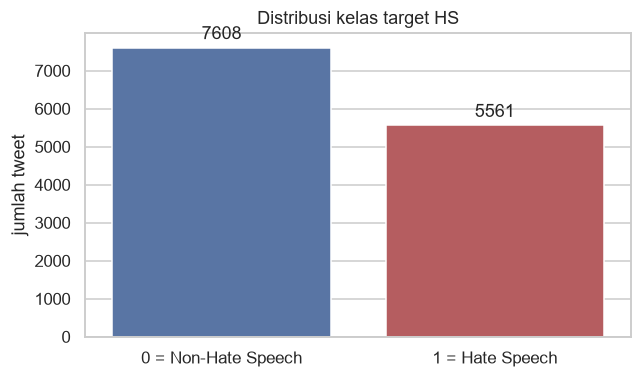

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.6))
sns.countplot(data=df, x="HS", hue="HS", legend=False,
              palette=["#4C72B0", "#C44E52"], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%d", padding=3)
ax.set_xticks([0, 1], ["0 = Non-Hate Speech", "1 = Hate Speech"])
ax.set_xlabel("")
ax.set_ylabel("jumlah tweet")
ax.set_title("Distribusi kelas target HS")
plt.tight_layout()
plt.show()

**Insight:** kelas tidak seimbang sempurna: 42,23% hate speech vs 57,77% non-hate speech. Baseline "selalu tebak kelas mayoritas"
sudah mendapat akurasi ~57,8% tanpa belajar apa pun. Karena itu **akurasi tidak boleh jadi metrik utama**;
gunakan **Macro F1** (memberi bobot sama pada kedua kelas) dan **Precision kelas 1** (melindungi kritik sah).

### Visualisasi 2 — Distribusi panjang tweet per kelas

**Pertanyaan:** apakah panjang teks membawa sinyal?

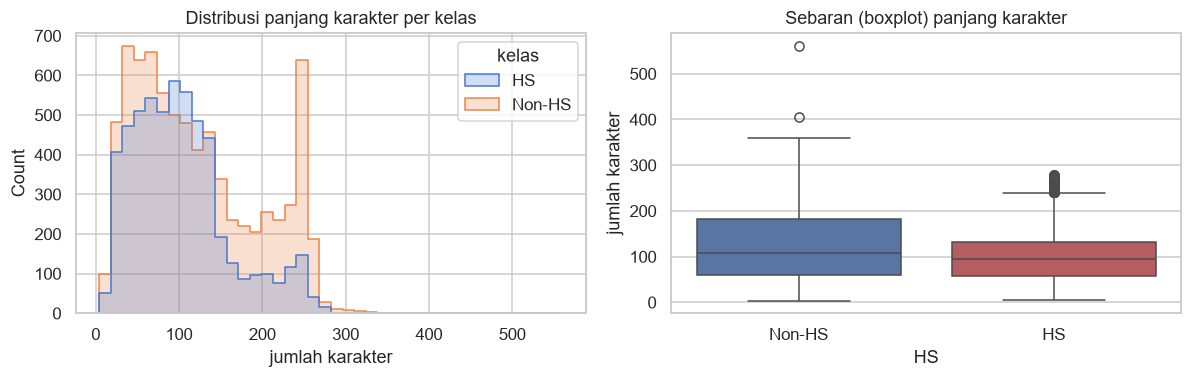

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(data=df.assign(char_length=chars, kelas=df["HS"].map({0: "Non-HS", 1: "HS"})),
             x="char_length", hue="kelas", bins=40, element="step",
             common_norm=False, ax=axes[0])
axes[0].set_title("Distribusi panjang karakter per kelas")
axes[0].set_xlabel("jumlah karakter")

sns.boxplot(data=df.assign(char_length=chars), x="HS", y="char_length",
            hue="HS", legend=False, palette=["#4C72B0", "#C44E52"], ax=axes[1])
axes[1].set_xticks([0, 1], ["Non-HS", "HS"])
axes[1].set_ylabel("jumlah karakter")
axes[1].set_title("Sebaran (boxplot) panjang karakter")
plt.tight_layout()
plt.show()

**Insight:** kelas HS justru **lebih pendek** (rata-rata 102 karakter, median 94) dibanding non-HS
(123 karakter, median 107). Pola ini masuk akal: ujaran kebencian sering berupa ejekan singkat,
sedangkan cuitan non-HS lebih banyak berisi penjelasan/argumen. Namun sebaran kedua kelas lebar dan
saling tumpang tindih, jadi panjang teks hanya **fitur pendukung**, bukan pembeda tunggal.
Karena sebaran right-skewed (maks 561 karakter), fitur ini perlu di-*scale*, bukan dihapus.

### Visualisasi 3 — Kata paling sering per kelas

**Pertanyaan:** kosakata apa yang membedakan kelas 0 dan 1?

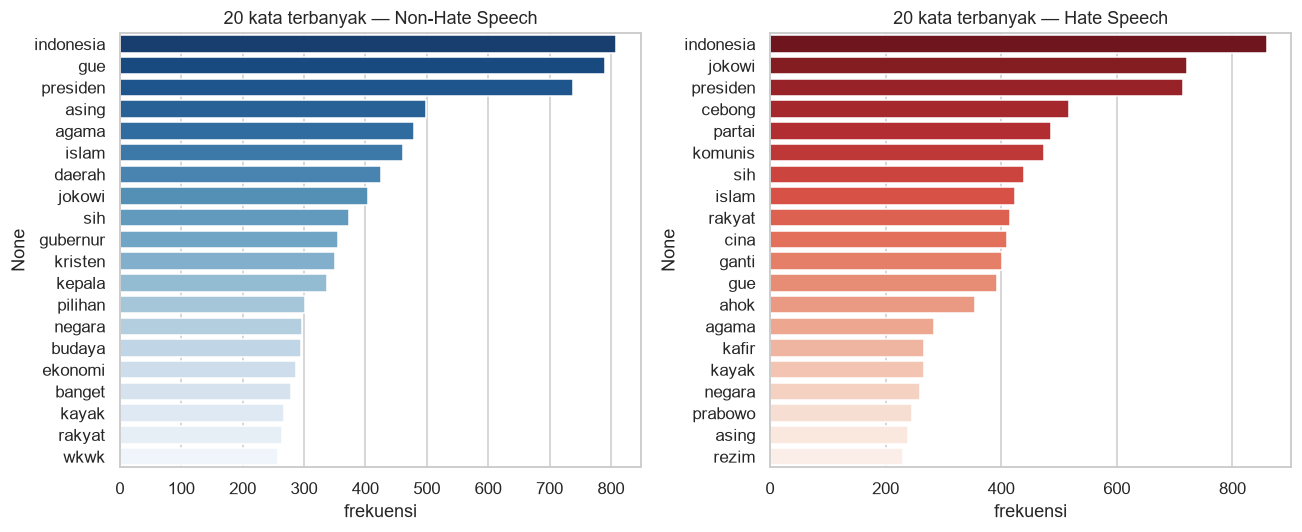

Top-10 Non-HS : ['indonesia', 'gue', 'presiden', 'asing', 'agama', 'islam', 'daerah', 'jokowi', 'sih', 'gubernur']
Top-10 HS     : ['indonesia', 'jokowi', 'presiden', 'cebong', 'partai', 'komunis', 'sih', 'islam', 'rakyat', 'cina']


In [17]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

EDA_STOPWORDS = set(StopWordRemoverFactory().get_stop_words())

def top_tokens(texts, k=20):
    """Frekuensi kata isi (stopword dibuang) agar yang tampil adalah kata bermakna."""
    tokens = Counter(w for t in texts for w in t.split() if w not in EDA_STOPWORDS)
    return pd.Series(dict(tokens.most_common(k)))

top_neg = top_tokens(eda_text[df["HS"] == 0])
top_pos = top_tokens(eda_text[df["HS"] == 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=top_neg.values, y=top_neg.index, hue=top_neg.index, legend=False,
            palette="Blues_r", ax=axes[0])
axes[0].set_title("20 kata terbanyak — Non-Hate Speech")
axes[0].set_xlabel("frekuensi")
sns.barplot(x=top_pos.values, y=top_pos.index, hue=top_pos.index, legend=False,
            palette="Reds_r", ax=axes[1])
axes[1].set_title("20 kata terbanyak — Hate Speech")
axes[1].set_xlabel("frekuensi")
plt.tight_layout()
plt.show()

print("Top-10 Non-HS :", list(top_neg.index[:10]))
print("Top-10 HS     :", list(top_pos.index[:10]))

**Insight:** setelah stopword dibuang, terlihat bahwa kelas HS didominasi **kosakata identitas & politik**
(`cebong`, `komunis`, `kafir`, `cina`, `rezim`) plus sejumlah kata kasar (`anjing`, `goblok`, `dungu`).
Hanya **11,4%** token kelas HS yang berasal dari `abusive.csv` (non-HS: 6,2%) — jadi kata kasar adalah
sinyal, tetapi bukan sinyal utama. Dua implikasi penting:
1. **Risiko bias:** kata identitas juga banyak di kelas non-HS (diskusi agama/etnis yang sah), sehingga
   model bisa salah menyensor diskusi wajar → False Positive. Ini alasan Precision kelas 1 diaudit ketat.
2. **Batas model leksikal:** karena sinyalnya berupa kombinasi konteks + identitas, TF-IDF hanya bisa
   menangkap permukaan; model kontekstual (IndoBERT) diperlukan untuk sarkasme/sindiran.
**Penting:** ini asosiasi dalam data, bukan bukti sebab-akibat.

### Visualisasi 4 — Rasio huruf kapital per kelas

**Pertanyaan:** apakah "berteriak" (caps) menandai ujaran kebencian?

      mean  median     max
HS                        
0   0.1129  0.0729  0.8824
1   0.1552  0.1043  0.8824


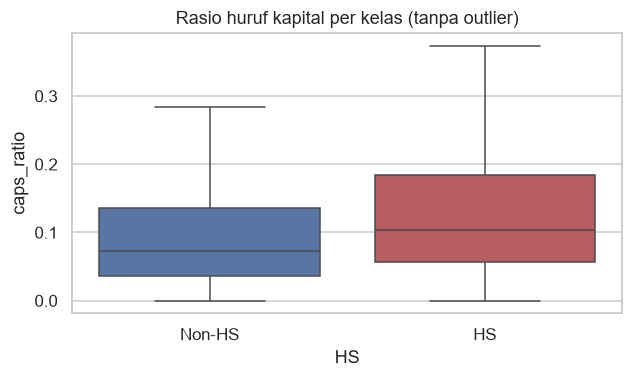

In [18]:
df["caps_ratio"] = tweet_str.map(lambda s: sum(ch.isupper() for ch in s) / (len(s) + 1))
print(df.groupby("HS")["caps_ratio"].agg(["mean", "median", "max"]).round(4).to_string())

fig, ax = plt.subplots(figsize=(6, 3.6))
sns.boxplot(data=df, x="HS", y="caps_ratio", hue="HS", legend=False,
            palette=["#4C72B0", "#C44E52"], ax=ax, showfliers=False)
ax.set_xticks([0, 1], ["Non-HS", "HS"])
ax.set_ylabel("caps_ratio")
ax.set_title("Rasio huruf kapital per kelas (tanpa outlier)")
plt.tight_layout()
plt.show()

**Insight:** kelas HS punya `caps_ratio` lebih tinggi (rata-rata 0,155 vs 0,113; median 0,104 vs 0,073).
Arahnya sesuai dugaan "berteriak = emosional", tetapi sebarannya sangat tumpang tindih dan banyak
nilai ekstrem — jadi fitur ini **pelengkap**, bukan penentu. Ini contoh kenapa fitur gaya penulisan
harus digabung dengan fitur teks, bukan dipakai sendirian.

### Visualisasi 5 — Porsi Hate Speech pada tweet bertopik pemerintahan

**Pertanyaan:** apakah subgrup wacana pemerintahan punya karakter berbeda? (audit SDG 16)

                  jumlah  proporsi_hs
non-pemerintahan    8968       0.3502
pemerintahan        4201       0.5761


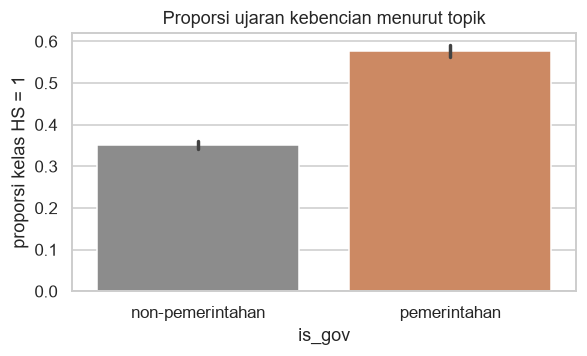

In [19]:
GOV_KEYWORDS = [
    "presiden", "jokowi", "prabowo", "ahok", "anies", "pemerintah", "menteri",
    "dpr", "negara", "rakyat", "rezim", "partai", "politik", "kpk", "polri",
    "polisi", "korupsi", "pajak", "undang", "perppu", "gubernur", "pilkada", "nkri",
]
gov_pattern = r"\b(?:" + "|".join(GOV_KEYWORDS) + r")\b"
df["is_gov"] = eda_text.str.contains(gov_pattern, regex=True).astype(int)

tabel_gov = df.groupby("is_gov")["HS"].agg(jumlah="size", proporsi_hs="mean").round(4)
tabel_gov.index = ["non-pemerintahan", "pemerintahan"]
print(tabel_gov.to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.4))
sns.barplot(data=df, x="is_gov", y="HS", hue="is_gov", legend=False,
            palette=["#8C8C8C", "#DD8452"], ax=ax)
ax.set_xticks([0, 1], ["non-pemerintahan", "pemerintahan"])
ax.set_ylabel("proporsi kelas HS = 1")
ax.set_title("Proporsi ujaran kebencian menurut topik")
plt.tight_layout()
plt.show()

**Insight:** 4.201 tweet (31,9%) memuat kata kunci pemerintahan, dan proporsi HS di subgrup itu
**57,6%** versus **35,0%** di luar subgrup. Subgrup ini cukup besar untuk diaudit pada Minggu 6.
**Penting:** ini **asosiasi**, bukan bukti sebab-akibat — kata kunci pemerintahan juga sering muncul
pada cuitan yang menyerang tokoh politik. Model tetap **tidak** diberi `is_gov` sebagai fitur, agar
tidak belajar "topik = kebencian".

## Ringkasan Bab 4

| Aspek | Temuan | Implikasi ke Bab 5 |
| :--- | :--- | :--- |
| Dimensi | 13.169 baris × 13 kolom, 3 file pendukung | Semua kolom konteks dipertahankan untuk error analysis |
| Missing | 0 sel kosong | Tidak perlu imputasi |
| Duplikat | 146 baris duplikat exact + 8 tweet berlabel konflik | Deduplikasi + buang label konflik **sebelum** split |
| Noise | token `USER`/`URL`/`RT`, kode hex, simbol, slang | Perlu cleaning bertahap + normalisasi kamus |
| Outlier | panjang teks ekor kanan; 24 baris (0,18%) di atas batas IQR, maks 561 karakter | Jangan dihapus; scale/cap saat pemodelan |
| Imbalance | 42,23% : 57,77% (1,37:1) | Cukup `class_weight='balanced'`, tanpa resampling |
| Topik | 31,9% tweet bertopik pemerintahan; proporsi HS 57,6% vs 35,0% | Audit subgrup di Minggu 6, bukan fitur |

**Keputusan yang dibawa ke `02_data_preparation.ipynb`:**
1. Buang 8 tweet berlabel konflik → 13.015 baris.
2. Deduplikasi teks exact → tidak ada teks sama di dua split.
3. Buat dua varian teks (contextual & lexical), stopword negasi selalu dipertahankan.
4. Split stratified 70/15/15 dengan `random_state=42` sebelum objek statistik apa pun di-fit.